In [ ]:
%pip install ipympl -qU

In [ ]:
try:
    from google.colab import output

    output.enable_custom_widget_manager()
except:
    pass

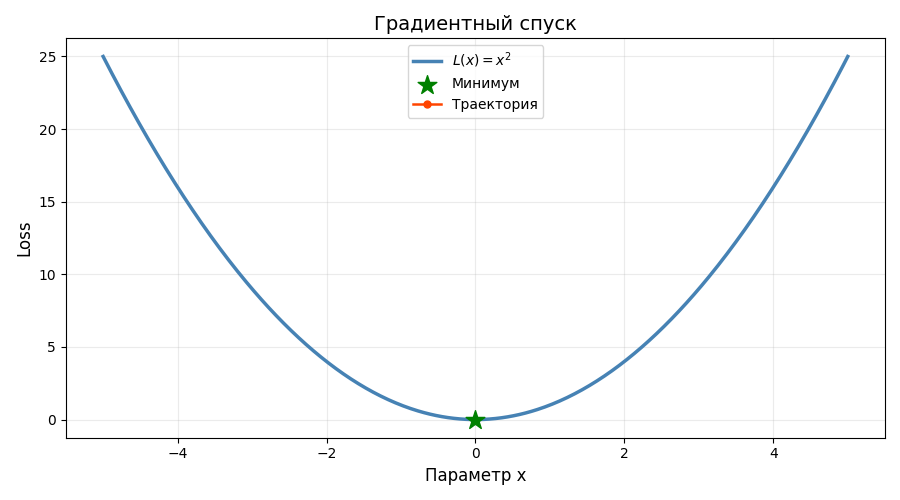

In [ ]:
# Визуализация влияния скорости обучения на процесс градиентного спуска.
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets


def loss(x):
    return x**2


def grad(x):
    return 2 * x


N_STEPS = 20

lr_slider = widgets.FloatSlider(
    value=0.1,
    min=0.01,
    max=1.5,
    step=0.01,
    description="Learning rate:",
    readout_format=".2f",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="500px"),
)

x0_slider = widgets.FloatSlider(
    value=4.0,
    min=-5.0,
    max=5.0,
    step=0.5,
    description="Начальный x:",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="500px"),
)

play = widgets.Play(
    value=0,
    min=0,
    max=N_STEPS,
    step=1,
    interval=300,
    description="Анимация",
)

step_slider = widgets.IntSlider(
    value=0,
    min=0,
    max=N_STEPS,
    step=1,
    description="Шаг:",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)


def sync_play(change):
    step_slider.value = change["new"]


play.observe(sync_play, names="value")

plt.ioff()

fig, ax = plt.subplots(figsize=(9, 5))

x_grid = np.linspace(-5, 5, 500)
ax.plot(x_grid, loss(x_grid), color="steelblue", linewidth=2.5, label=r"$L(x)=x^2$")

ax.scatter([0], [0], color="green", marker="*", s=200, zorder=5, label="Минимум")

(trajectory,) = ax.plot(
    [], [], "o-", color="orangered", linewidth=1.8, markersize=5, label="Траектория"
)

(current_point,) = ax.plot(
    [],
    [],
    "o",
    color="red",
    markersize=11,
    markeredgecolor="white",
    markeredgewidth=1.5,
    zorder=6,
)

ax.set_xlabel("Параметр x", fontsize=12)
ax.set_ylabel("Loss", fontsize=12)
ax.set_title("Градиентный спуск", fontsize=14)
ax.grid(alpha=0.25)
ax.legend(loc="upper center")

fig.tight_layout()
fig.canvas.header_visible = False

info = widgets.HTML()


def update(change=None):
    lr = lr_slider.value
    x0 = x0_slider.value
    step = step_slider.value

    xs = [x0]

    for _ in range(N_STEPS):
        xs.append(xs[-1] - lr * grad(xs[-1]))

    xs = np.asarray(xs)
    losses = loss(xs)

    visible_xs = xs[: step + 1]
    visible_losses = losses[: step + 1]

    trajectory.set_data(visible_xs, visible_losses)

    current_x = xs[step]
    current_loss = losses[step]

    current_point.set_data([current_x], [current_loss])

    max_x = max(5.0, np.max(np.abs(visible_xs)) * 1.15 + 0.5)
    max_y = max(25.0, np.max(visible_losses) * 1.15 + 1.0)

    ax.set_xlim(-max_x, max_x)
    ax.set_ylim(-0.5, max_y)

    ax.set_title(f"Градиентный спуск | LR = {lr:.2f} | Шаг = {step}")

    if np.isclose(lr, 0.5):
        mode = "Минимум достигается за один шаг"
    elif lr < 0.5:
        mode = "Сходимость без перескакивания через минимум"
    elif lr < 1.0:
        mode = "Сходимость с колебаниями"
    elif np.isclose(lr, 1.0):
        mode = "Колебания без уменьшения Loss"
    else:
        mode = "Расходимость: learning rate слишком большой"

    info.value = f"""
    <div style="font-size:14px; line-height:1.8">
        <b>Текущий шаг:</b> {step} / {N_STEPS}<br>
        <b>x:</b> {current_x:.6g}<br>
        <b>Loss:</b> {current_loss:.6g}<br>
        <b>Градиент:</b> {grad(current_x):.6g}<br>
        <b>Режим:</b> {mode}
    </div>
    """

    fig.canvas.draw_idle()


lr_slider.observe(update, names="value")
x0_slider.observe(update, names="value")
step_slider.observe(update, names="value")

controls = widgets.VBox(
    [
        widgets.HTML("<h3>Интерактивный градиентный спуск</h3>"),
        lr_slider,
        x0_slider,
        widgets.HBox([play, step_slider]),
        info,
    ]
)

display(controls)
display(fig.canvas)

update()